# Lab 1 – podstawowa analiza obrazu

W tym ćwiczeniu samodzielnie przeprowadzisz podstawową analizę obrazu cyfrowego z wykorzystaniem biblioteki `scikit-image`.

Twoim celem jest przejście przez cały prosty proces analizy:

**wczytanie obrazu → sprawdzenie jego właściwości → analiza kanałów → skala szarości → histogram → normalizacja → wyrównanie histogramu**


## 1. Wybierz obraz

Wybierz jeden obraz z wbudowanej bazy:

```python
skimage.data
```

Możesz wykorzystać np.:

```python
data.camera()
data.coins()
data.chelsea()
data.coffee()
data.horse()
data.moon()
data.rocket()
```

Nie wybieraj obrazu `astronaut`, ponieważ był już analizowany podczas zajęć.

Wyświetl wybrany obraz.


In [74]:
from skimage import io, data, color, exposure
from skimage.util import  img_as_float
import numpy as np
import matplotlib.pyplot as plt

# Wczytaj wybrany obraz
# img = img_as_float(io.imread("mietek.png"))
img = img_as_float(data.chelsea())

# Wyświetl obraz


## 2. Sprawdź podstawowe informacje o obrazie

Sprawdź:

```python
img.shape
img.dtype
img.min()
img.max()
```

Zwróć uwagę na:

- wymiary obrazu,
- liczbę kanałów,
- typ danych,
- minimalną i maksymalną wartość pikseli.

### Zastanów się

Co informacje zwracane przez `shape` mówią o obrazie?  
Czy wartości pikseli są zapisane w zakresie `0–255`, czy `0–1`?


In [75]:
print("Wymiary obrazu:", img.shape)
print("Typ danych:", img.dtype)
print("Minimalna wartość:", img.min())
print("Maksymalna wartość:", img.max())


Wymiary obrazu: (300, 451, 3)
Typ danych: float64
Minimalna wartość: 0.0
Maksymalna wartość: 0.9058823529411765


## 3. Określ rodzaj obrazu

Na podstawie wymiarów określ, czy obraz jest:

- obrazem w skali szarości,
- obrazem RGB,
- obrazem RGBA.

Przykładowo:

```text
(wysokość, szerokość)
```

oznacza zazwyczaj obraz w skali szarości,

natomiast:

```text
(wysokość, szerokość, 3)
```

oznacza obraz RGB.


## 4. Przeanalizuj kanały obrazu

Jeżeli wybrany obraz jest obrazem RGB, wydziel jego trzy kanały:

- R – czerwony,
- G – zielony,
- B – niebieski.

Wyświetl obok siebie:

**obraz RGB | kanał R | kanał G | kanał B**

Kanały możesz wyświetlić w skali szarości, ponieważ wtedy jasność piksela pokazuje intensywność danego kanału.

### Zastanów się

W których fragmentach obrazu poszczególne kanały są najjaśniejsze?  
Czy da się powiązać to z kolorami widocznymi na obrazie oryginalnym?

Jeśli obraz jest już w skali szarości, pomiń ten etap.


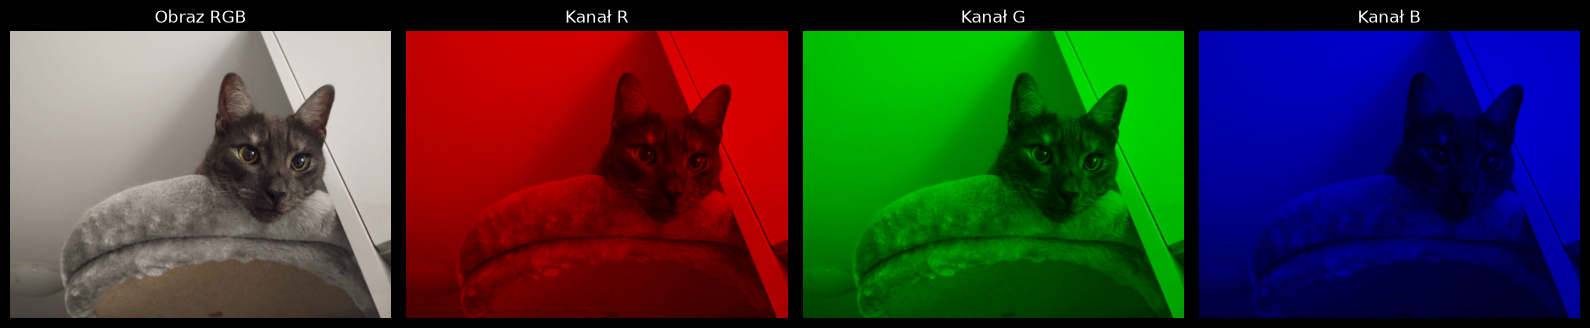

In [76]:
# Jeśli obraz jest RGB, wyświetl jego kanały R, G i B
img = io.imread("mietek.png")
red = np.zeros_like(img)
green = np.zeros_like(img)
blue = np.zeros_like(img)
red[:, :, 0] = img[:, :, 0]
green[:, :, 1] = img[:, :, 1]
blue[:,:,2] = img[:,:,2]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img)
axes[0].set_title("Obraz RGB")
axes[0].axis("off")

axes[1].imshow(red)
axes[1].set_title("Kanał R")
axes[1].axis("off")

axes[2].imshow(green)
axes[2].set_title("Kanał G")
axes[2].axis("off")

axes[3].imshow(blue)
axes[3].set_title("Kanał B")
axes[3].axis("off")

plt.tight_layout()
plt.show()


## 5. Przekonwertuj obraz do skali szarości

Jeżeli obraz jest kolorowy, przekonwertuj go do skali szarości:

```python
gray = color.rgb2gray(img)
```

Wyświetl obraz przed i po konwersji.

Ponownie sprawdź:

```python
gray.shape
gray.dtype
gray.min()
gray.max()
```

### Zastanów się

Co zmieniło się w strukturze danych po usunięciu informacji o kolorze?


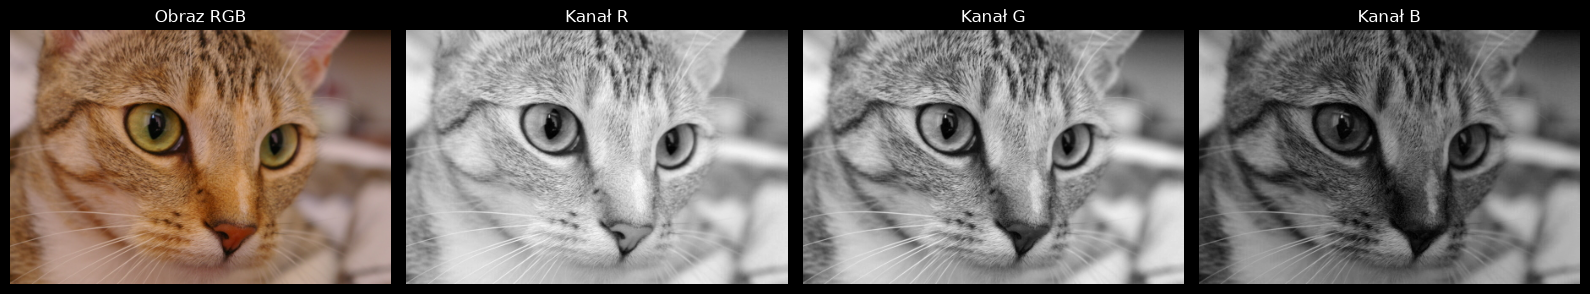

In [77]:
# Utwórz obraz w skali szarości
img = data.chelsea()
# img = io.imread("mietek.png")
gray = color.rgb2gray(img)
if img.ndim == 2:
    img_rgb = np.stack([img, img, img], axis=-1)
elif img.shape[2] == 4:
    img_rgb = img[:, :, :3]
else:
    img_rgb = img

red = np.zeros_like(img)
green = np.zeros_like(img)
blue = np.zeros_like(img)
red[:, :, 0] = img[:, :, 0]
green[:, :, 1] = img[:, :, 1]
blue[:,:,2] = img[:,:,2]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img)
axes[0].set_title("Obraz RGB")
axes[0].axis("off")

axes[1].imshow(color.rgb2gray(red), cmap="gray")
axes[1].set_title("Kanał R")
axes[1].axis("off")

axes[2].imshow(color.rgb2gray(green), cmap="gray")
axes[2].set_title("Kanał G")
axes[2].axis("off")

axes[3].imshow(color.rgb2gray(blue), cmap="gray")
axes[3].set_title("Kanał B")
axes[3].axis("off")

plt.tight_layout()
plt.show()


## 6. Narysuj histogram jasności

Dla obrazu w skali szarości utwórz histogram.

Użyj:

```python
bins=256
```

Pamiętaj, aby zakres histogramu odpowiadał zakresowi wartości pikseli.

Dla obrazu w zakresie `0–1`:

```python
range=(0, 1)
```

Dla obrazu w zakresie `0–255`:

```python
range=(0, 255)
```

Podpisz osie:

- oś X – poziom jasności,
- oś Y – liczba pikseli.

### Zastanów się

Czy większość pikseli znajduje się w obszarze ciemnych, średnich czy jasnych wartości?  
Czy histogram wykorzystuje szeroki zakres intensywności, czy wartości są skupione w niewielkim obszarze?


In [78]:
# Narysuj histogram obrazu w skali szarości



## 7. Wykonaj normalizację

Wykonaj normalizację obrazu za pomocą:

```python
exposure.rescale_intensity()
```

Przeskaluj wartości pikseli do zakresu:

```text
0–1
```

Wyświetl:

**obraz przed normalizacją | obraz po normalizacji**

Narysuj również histogramy obu obrazów.

### Zastanów się

Czy zakres wartości został rozciągnięty?  
Czy kontrast obrazu zmienił się zauważalnie?  
Jeżeli zmiana jest niewielka, spróbuj wyjaśnić, z czego może to wynikać.


In [79]:
# Wykonaj normalizację i porównaj obraz przed i po normalizacji



## 8. Wykonaj wyrównanie histogramu

Wykonaj wyrównanie histogramu:

```python
exposure.equalize_hist()
```

Wyświetl:

**obraz przed wyrównaniem | obraz po wyrównaniu**

Narysuj histogram obrazu wynikowego.

### Zastanów się

Jak zmienił się rozkład poziomów jasności?  
Czy szczegóły obrazu stały się bardziej widoczne?  
Czy histogram jest bardziej rozłożony w całym dostępnym zakresie?


In [80]:
# Wykonaj wyrównanie histogramu i wyświetl wynik



## 9. Porównaj wyniki

Na jednej figurze wyświetl:

```text
Oryginał | Normalizacja | Wyrównanie histogramu
```

Poniżej umieść odpowiadające im histogramy.

Porównaj wygląd obrazów i rozkład intensywności.

### Zastanów się nad różnicą pomiędzy normalizacją i wyrównaniem histogramu

Normalizacja przede wszystkim rozciąga zakres wartości, natomiast wyrównanie histogramu zmienia sposób rozmieszczenia intensywności w tym zakresie.


In [81]:
# Porównaj obraz oryginalny, po normalizacji i po wyrównaniu histogramu

